Decision Tree Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      Canned       1.00      1.00      1.00         3
       Dried       1.00      1.00      1.00         2
       Fresh       1.00      1.00      1.00         6
      Frozen       1.00      1.00      1.00         2
       Juice       1.00      1.00      1.00         3

    accuracy                           1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16


Confusion Matrix:
[[3 0 0 0 0]
 [0 2 0 0 0]
 [0 0 6 0 0]
 [0 0 0 2 0]
 [0 0 0 0 3]]


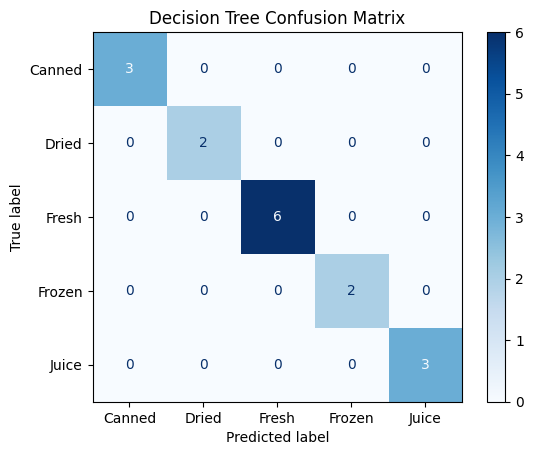

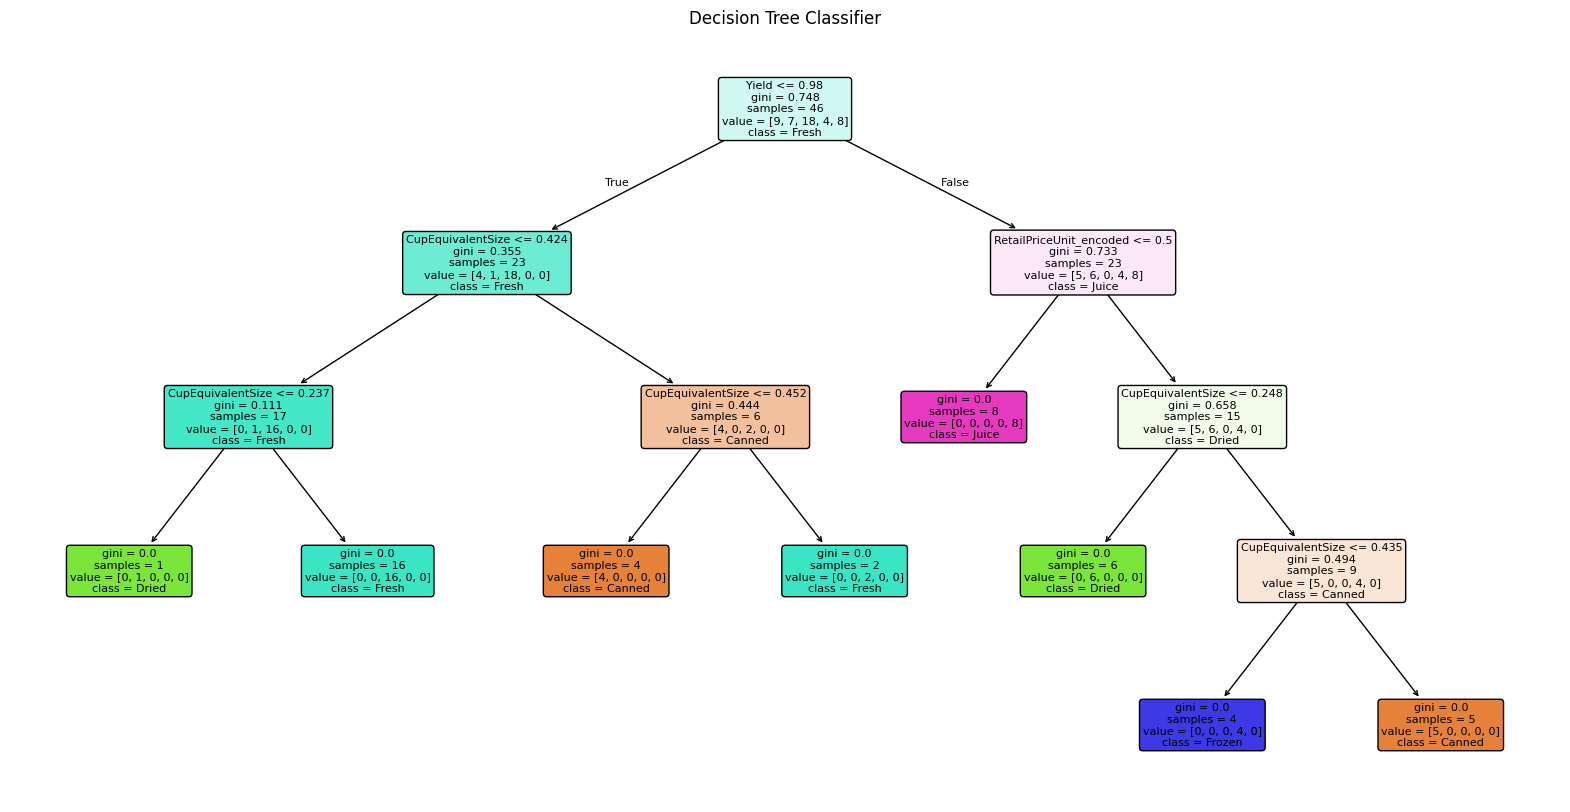

In [4]:


import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load cleaned dataset
df = pd.read_csv('Fruit_Prices_2022_Cleaned.xls')

# 2. Encode categorical columns
le_form = LabelEncoder()
df['Form_encoded'] = le_form.fit_transform(df['Form'])

le_retail = LabelEncoder()
df['RetailPriceUnit_encoded'] = le_retail.fit_transform(
    df['RetailPriceUnit']
)

le_cup = LabelEncoder()
df['CupEquivalentUnit_encoded'] = le_cup.fit_transform(
    df['CupEquivalentUnit']
)

# 3. Features and target
X = df[
    [
        'RetailPrice',
        'Yield',
        'CupEquivalentSize',
        'CupEquivalentPrice',
        'RetailPriceUnit_encoded',
        'CupEquivalentUnit_encoded'
    ]
]

y = df['Form_encoded']

# 4. Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# 5. Create Decision Tree Classifier
dt = DecisionTreeClassifier(
    random_state=42
)

# 6. Train the Decision Tree
dt.fit(X_train, y_train)

# 7. Make predictions
y_pred = dt.predict(X_test)

# 8. Accuracy
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred))

# 9. Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=le_form.classes_
    )
)

# 10. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le_form.classes_
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Decision Tree Confusion Matrix")
plt.show()

# 11. Display Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    dt,
    feature_names=X.columns,
    class_names=le_form.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier")
plt.show()

